In [7]:
import pandas as pd

# Importer le fichier CSV
df = pd.read_csv("bank_customers.csv")

# 1. Nombre de lignes et de colonnes
print("Nombre de lignes et colonnes :", df.shape)

# 2. Noms des colonnes
print("\nNoms des colonnes :")
print(df.columns.tolist())

# 3. Les 5 premières lignes
print("\n5 premières lignes :")
print(df.head())

# 4. Types des variables
print("\nTypes des variables :")
print(df.dtypes)

Nombre de lignes et colonnes : (2012, 11)

Noms des colonnes :
['customer_id', 'age', 'city', 'monthly_income_mad', 'balance_mad', 'num_products', 'monthly_transactions', 'complaints_last_12m', 'has_savings_product', 'customer_segment', 'churn']

5 premières lignes :
  customer_id  age        city  monthly_income_mad  balance_mad  num_products  \
0       C0001   43      Tanger              6239.0      28447.0             2   
1       C0002   25      Agadir              5547.0      35976.0             2   
2       C0003   49         Fès             10157.0      46925.0             3   
3       C0004   51  Casablanca              9189.0      96636.0             3   
4       C0005   18         Fès              3694.0      29882.0             2   

   monthly_transactions  complaints_last_12m  has_savings_product  \
0                    26                    0                    0   
1                    27                    0                    1   
2                    21               

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# 1. Valeurs manquantes par colonne
print("Valeurs manquantes :")
print(df.isnull().sum())

# 2. Nombre total de doublons
print("\nNombre de doublons :")
print(df.duplicated().sum())

Valeurs manquantes :
customer_id              0
age                      0
city                    16
monthly_income_mad      28
balance_mad             22
num_products             0
monthly_transactions     0
complaints_last_12m      0
has_savings_product      0
customer_segment         0
churn                    0
dtype: int64

Nombre de doublons :
12


In [10]:
# Statistiques descriptives
df.describe()

,age,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m,has_savings_product,churn
count,2012.000000,1984.000000,1990.000000,2012.000000,2012.000000,2012.000000,2012.000000,2012.000000
mean,38.611332,9402.492944,38280.522111,2.758449,24.221670,0.469185,0.421968,0.056163
std,12.540418,5615.605311,37825.803593,1.273336,5.020155,0.667901,0.493996,0.230294
min,-3.000000,2500.000000,0.000000,1.000000,8.000000,0.000000,0.000000,0.000000
25%,30.000000,5532.750000,12395.750000,2.000000,21.000000,0.000000,0.000000,0.000000
50%,39.000000,8065.500000,28576.000000,3.000000,24.000000,0.000000,0.000000,0.000000
75%,47.000000,11679.500000,52058.250000,4.000000,27.000000,1.000000,1.000000,0.000000
max,120.000000,43734.000000,364585.000000,6.000000,42.000000,4.000000,1.000000,1.000000


In [11]:
df = df.drop_duplicates()

In [12]:
print("Nombre de doublons après suppression :", df.duplicated().sum())

Nombre de doublons après suppression : 0


In [13]:
df.shape

(2000, 11)

In [14]:
df[df["age"] < 18]

,customer_id,age,city,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m,has_savings_product,customer_segment,churn
461,C0462,-3,Rabat,3885.0,14141.0,2,14,0,0,Young,0
1478,C1479,5,Marrakech,14959.0,96636.0,2,32,0,0,Professional,0


In [15]:
df[df["age"] > 90]

,customer_id,age,city,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m,has_savings_product,customer_segment,churn
522,C0523,120,Tanger,7112.0,24084.0,2,28,1,0,Mass Market,0
1956,C1957,99,Tanger,5267.0,5609.0,1,22,1,0,Mass Market,0


In [16]:
import numpy as np

In [17]:
df.loc[(df["age"] < 18) | (df["age"] > 90), "age"] = np.nan

In [18]:
df["age"].isnull().sum()

np.int64(4)

In [19]:
df["city"] = df["city"].fillna("Unknown")

In [20]:
df["city"].isnull().sum()

np.int64(0)

In [21]:
df["monthly_income_mad"].median()

8061.5

In [22]:
df["balance_mad"].median()

28466.5

In [23]:
df["monthly_income_mad"] = df["monthly_income_mad"].fillna(
    df["monthly_income_mad"].median()
)

df["balance_mad"] = df["balance_mad"].fillna(
    df["balance_mad"].median()
)

In [24]:
df.isnull().sum()

,0
customer_id,0
age,4
city,0
monthly_income_mad,0
balance_mad,0
num_products,0
monthly_transactions,0
complaints_last_12m,0
has_savings_product,0
customer_segment,0


In [25]:
df["age"].median()

39.0

In [26]:
df["age"] = df["age"].fillna(df["age"].median())

In [27]:
df.isnull().sum()

,0
customer_id,0
age,0
city,0
monthly_income_mad,0
balance_mad,0
num_products,0
monthly_transactions,0
complaints_last_12m,0
has_savings_product,0
customer_segment,0


In [28]:
cols = [
    "age",
    "monthly_income_mad",
    "balance_mad",
    "num_products",
    "monthly_transactions",
    "complaints_last_12m"
]

In [29]:
df[cols].describe().round(2)

,age,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,38.63,9382.61,38114.27,2.76,24.23,0.47
std,12.28,5586.02,37682.49,1.27,5.03,0.67
min,18.00,2500.00,0.00,1.00,8.00,0.00
25%,30.00,5550.50,12461.00,2.00,21.00,0.00
50%,39.00,8061.50,28466.50,3.00,24.00,0.00
75%,47.00,11597.75,51659.75,4.00,27.00,1.00
max,75.00,43734.00,364585.00,6.00,42.00,4.00


### Key Insights – Customer Overview

- The average customer age is approximately **39 years**, with ages ranging from 18 to 75.
- Customers have a median monthly income of approximately **8,062 MAD**.
- The median account balance is approximately **28,467 MAD**.
- On average, customers hold around **3 banking products**.
- Customers perform approximately **24 transactions per month** on average.
- Income and account balances show some high values, suggesting the presence of different customer financial profiles.

### 4.2 Age Distribution

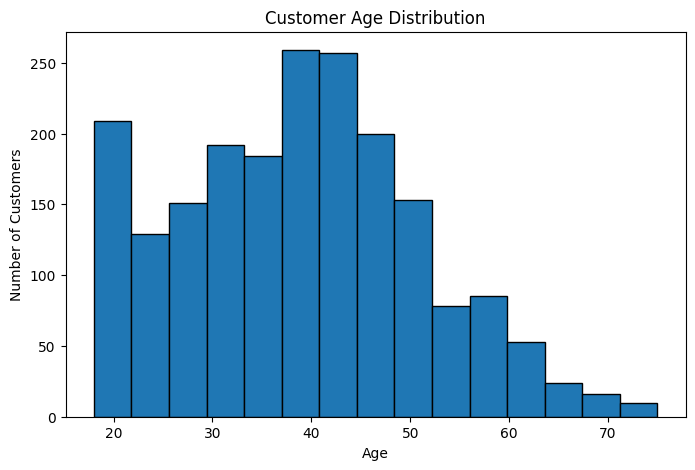

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["age"], bins=15, edgecolor="black")

plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.title("Customer Age Distribution")

plt.show()

#### Key Insight

The customer base is mainly concentrated between **30 and 50 years old**.  
The number of customers gradually decreases after the age of 50, indicating a smaller representation of older customers.

### 4.3 Customer Segmentation

In [31]:
df["customer_segment"].value_counts()

,count
customer_segment,
Mass Market,897
Young,433
Professional,399
Affluent,271


In [32]:
df["customer_segment"].value_counts(normalize=True) * 100

,proportion
customer_segment,
Mass Market,44.85
Young,21.65
Professional,19.95
Affluent,13.55


Mass Market is the largest customer segment, representing approximately 45% of the total customer base.

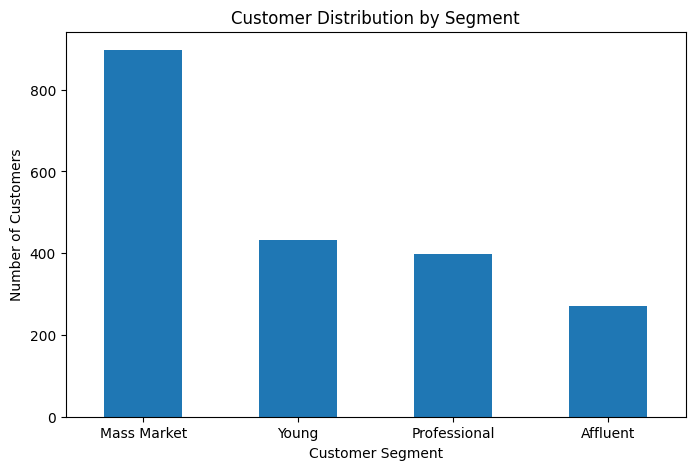

In [33]:
segment_counts = df["customer_segment"].value_counts()

plt.figure(figsize=(8, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

#### Key Insight

The Mass Market segment is the largest customer segment, representing approximately 45% of the customer base.

This segment may represent an important opportunity for the bank to increase product penetration. Further analysis is needed to identify which banking products could best match the needs and financial profiles of these customers.

In [34]:
df.groupby("customer_segment")["num_products"].mean().round(2)

,num_products
customer_segment,
Affluent,2.86
Mass Market,2.79
Professional,2.63
Young,2.76


#### Key Insight

The average number of banking products is relatively similar across customer segments.

Affluent customers hold the highest average number of products (2.86), while Professional customers hold the lowest (2.63).

Overall, the differences remain small, suggesting that customer segment alone may not strongly influence the number of products held.

4.5 — Financial Profile by Customer Segment.

In [35]:
df.groupby("customer_segment")[
    ["monthly_income_mad", "balance_mad"]
].mean().round(2)

,monthly_income_mad,balance_mad
customer_segment,,
Affluent,9280.08,41000.80
Mass Market,9479.11,37198.40
Professional,9590.69,40600.93
Young,9055.14,35913.59


#### Key Insight

Professional customers have the highest average monthly income (9,590.69 MAD), while Affluent customers have the highest average account balance (41,000.80 MAD).

Young customers show the lowest average income and account balance.

However, the differences between customer segments remain relatively limited, suggesting that other variables should also be considered when identifying high-potential customers.

### 4.6 Savings Product Analysis

In [36]:
df["has_savings_product"].value_counts()

,count
has_savings_product,
0,1160
1,840


In [37]:
df["has_savings_product"].value_counts(normalize=True).mul(100).round(2)

,proportion
has_savings_product,
0,58.0
1,42.0


In [38]:
df.groupby("has_savings_product")[
    ["monthly_income_mad", "balance_mad", "num_products", "monthly_transactions"]
].mean().round(2)

,monthly_income_mad,balance_mad,num_products,monthly_transactions
has_savings_product,,,,
0,8414.16,26748.88,2.68,24.25
1,10719.99,53809.33,2.87,24.20


#### Key Insight

Customers with a savings product show a stronger financial profile than customers without one.

Their average account balance is approximately **53,809 MAD**, compared with **26,749 MAD** for customers without a savings product.

They also have a higher average monthly income (**10,720 MAD vs. 8,414 MAD**).

In contrast, monthly transaction activity is almost identical between the two groups.

These results suggest that **income and account balance may be useful variables for identifying potential savings-product customers**.

4.7 — Potential Savings Customers

In [39]:
non_savers = df[df["has_savings_product"] == 0]

In [40]:
non_savers[
    ["monthly_income_mad", "balance_mad"]
].describe().round(2)

,monthly_income_mad,balance_mad
count,1160.00,1160.00
mean,8414.16,26748.88
std,4731.38,26001.76
min,2500.00,0.00
25%,5196.00,7852.50
50%,7481.00,20482.50
75%,10484.25,37675.25
max,37577.00,183482.00


### 4.8 Identification of High-Potential Savings Customers

Among customers without a savings product, the 75th percentile is:

- **Monthly income:** 10,484.25 MAD
- **Account balance:** 37,675.25 MAD

For this analysis, a customer is considered **high potential** if they have both a monthly income and an account balance above these thresholds.

This rule allows us to identify financially strong customers who do not currently hold a savings product and could represent potential targets for a savings campaign.

In [41]:
high_potential = non_savers[
    (non_savers["monthly_income_mad"] >= 10484.25) &
    (non_savers["balance_mad"] >= 37675.25)
]

high_potential.shape

(140, 11)

In [42]:
high_potential_percentage = (
    len(high_potential) / len(non_savers)
) * 100

round(high_potential_percentage, 2)

12.07

#### Key Insight

The analysis identified **140 high-potential customers** among the 1,160 customers who do not currently hold a savings product.

These customers represent approximately **12.1% of non-savers**.

They combine relatively high monthly income and account balances, making them a relevant target group for a potential savings-product campaign.

In [43]:
high_potential["customer_segment"].value_counts()

,count
customer_segment,
Mass Market,61
Professional,34
Young,27
Affluent,18


In [44]:
df.groupby("customer_segment")["has_savings_product"].mean().mul(100).round(2)

,has_savings_product
customer_segment,
Affluent,46.86
Mass Market,41.47
Professional,40.10
Young,41.80


#### Key Insight – Savings Product by Segment

Affluent customers have the highest savings-product adoption rate at **46.86%**.

The adoption rates for Young (41.80%), Mass Market (41.47%), and Professional customers (40.10%) are relatively similar.

Although Affluent customers show the highest adoption rate, more than half of them still do not hold a savings product, indicating additional cross-selling potential.

4.9 — Churn Analysis.

In [45]:
df["churn"].value_counts()

,count
churn,
0,1889
1,111


In [46]:
df["churn"].value_counts(normalize=True).mul(100).round(2)

,proportion
churn,
0,94.45
1,5.55


### 4.9 Churn Analysis

Among the 2,000 customers, **111 customers have churned**, representing a churn rate of approximately **5.55%**.

The objective of this analysis is to identify the characteristics associated with churn and determine which customers may require stronger retention actions.

In [47]:
df.groupby("churn")[
    [
        "age",
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "complaints_last_12m"
    ]
].mean().round(2)

,age,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m
churn,,,,,,
0,38.56,9413.25,38309.84,2.78,24.26,0.45
1,39.86,8861.16,34786.00,2.39,23.70,0.72


#### Key Insight – Churn Drivers

Customers who churn show a higher average number of complaints (**0.72**) compared with customers who remain (**0.45**).

Churned customers also hold fewer banking products on average (**2.39 vs. 2.78**).

Differences in age, income and transaction activity are relatively limited.

These results suggest that **customer complaints and product engagement may be important indicators associated with churn**.

In [48]:
df.groupby("complaints_last_12m")["churn"].mean().mul(100).round(2)

,churn
complaints_last_12m,
0,4.46
1,6.34
2,9.16
3,16.67
4,100.00


In [49]:
df.groupby("complaints_last_12m").agg(
    customers=("customer_id", "count"),
    churned_customers=("churn", "sum"),
    churn_rate=("churn", "mean")
).round(3)

,customers,churned_customers,churn_rate
complaints_last_12m,,,
0,1234,55,0.045
1,615,39,0.063
2,131,12,0.092
3,18,3,0.167
4,2,2,1.000


#### Key Insight – Complaints and Customer Churn

The churn rate increases as the number of customer complaints rises:

- 0 complaints: **4.5% churn**
- 1 complaint: **6.3% churn**
- 2 complaints: **9.2% churn**
- 3 complaints: **16.7% churn**

Customers with 4 complaints show a 100% churn rate, but this group contains only 2 customers. Therefore, this result should be interpreted with caution.

Overall, the analysis suggests a strong association between repeated complaints and customer churn.

**Business recommendation:** Customers with multiple complaints should be prioritized for proactive retention actions, such as rapid complaint resolution and personalized follow-up.

In [50]:
df.groupby("num_products").agg(
    customers=("customer_id", "count"),
    churned_customers=("churn", "sum"),
    churn_rate=("churn", "mean")
).round(3)

,customers,churned_customers,churn_rate
num_products,,,
1,316,27,0.085
2,630,43,0.068
3,541,20,0.037
4,318,14,0.044
5,121,6,0.050
6,74,1,0.014


#### Key Insight – Product Engagement and Churn

Customers with fewer banking products show higher churn rates:

- 1 product: **8.5%**
- 2 products: **6.8%**
- 3 products: **3.7%**
- 4 products: **4.4%**
- 5 products: **5.0%**
- 6 products: **1.4%**

Overall, customers with only one or two products appear to be more exposed to churn.

This suggests that stronger product engagement may be associated with customer retention, although the relationship is not perfectly linear.

**Business recommendation:** The bank could identify customers with only one or two products and evaluate relevant cross-selling opportunities while monitoring their satisfaction and needs.

### 4.10 Identification of Customers at Risk

Previous analysis identified two important indicators associated with customer churn:

- Repeated customer complaints
- Low product engagement

For this analysis, customers with **at least 2 complaints in the last 12 months** and **1 or 2 banking products** are considered a priority group for retention actions.

In [51]:
at_risk = df[
    (df["complaints_last_12m"] >= 2) &
    (df["num_products"] <= 2)
]

at_risk.shape

(80, 11)

In [52]:
at_risk["churn"].value_counts()

,count
churn,
0,68
1,12


In [53]:
at_risk["churn"].mean() * 100

np.float64(15.0)

#### Key Insight – At-Risk Customers

The rule identified **80 customers** with at least 2 complaints and no more than 2 banking products.

This group has a **15% churn rate**, compared with only **5.55% for the overall customer base**.

Therefore, customers in this group show a churn rate approximately **2.7 times higher than average**.

This suggests that combining repeated complaints with low product engagement can help identify customers who may require priority retention actions.

**Business recommendation:** The bank should proactively monitor these customers, prioritize complaint resolution, conduct personalized follow-ups, and assess relevant product offers to strengthen customer engagement.

### 4.11 Young Customers Analysis

The objective of this analysis is to understand the financial profile and banking behavior of young customers in order to identify relevant product opportunities.

In [54]:
young_customers = df[df["customer_segment"] == "Young"]

young_customers.shape

(433, 11)

In [55]:
young_customers[
    [
        "age",
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "complaints_last_12m"
    ]
].describe().round(2)

,age,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m
count,433.00,433.00,433.00,433.00,433.00,433.00
mean,38.74,9055.14,35913.59,2.76,23.90,0.48
std,11.95,5730.46,36052.57,1.30,5.16,0.67
min,18.00,2500.00,0.00,1.00,9.00,0.00
25%,30.00,5200.00,13016.00,2.00,20.00,0.00
50%,39.00,7627.00,24877.00,3.00,24.00,0.00
75%,46.00,11261.00,46925.00,4.00,27.00,1.00
max,75.00,38514.00,293761.00,6.00,42.00,3.00


### 4.11 Young Customers Analysis

The existing `customer_segment = "Young"` category does not correspond strictly to customer age, as customers in this segment range from 18 to 75 years old.

Therefore, for this analysis, young customers are defined as customers aged **18 to 30 years old**.

In [56]:
young_customers = df[
    (df["age"] >= 18) &
    (df["age"] <= 30)
]

young_customers.shape

(538, 11)

In [57]:
young_customers[
    [
        "age",
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "has_savings_product",
        "complaints_last_12m"
    ]
].mean().round(2)

,0
age,23.42
monthly_income_mad,9485.72
balance_mad,38389.19
num_products,2.70
monthly_transactions,24.07
has_savings_product,0.41
complaints_last_12m,0.48


In [58]:
df["age_group"] = np.where(
    df["age"] <= 30,
    "18-30",
    "31+"
)

df.groupby("age_group")[
    [
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "has_savings_product",
        "complaints_last_12m",
        "churn"
    ]
].mean().round(2)

,monthly_income_mad,balance_mad,num_products,monthly_transactions,has_savings_product,complaints_last_12m,churn
age_group,,,,,,,
18-30,9485.72,38389.19,2.70,24.07,0.41,0.48,0.05
31+,9344.67,38013.10,2.78,24.29,0.43,0.47,0.06


#### Key Insight – Savings Product by Age Group

Customers aged 31 and above show a higher savings-product adoption rate than customers aged 18–30.

This suggests that younger customers may represent an opportunity for targeted savings-product campaigns adapted to their financial profile.

In [59]:
young_customers["has_savings_product"].value_counts()

,count
has_savings_product,
0,320
1,218


In [60]:
young_customers["has_savings_product"].value_counts(normalize=True).mul(100).round(2)

,proportion
has_savings_product,
0,59.48
1,40.52


#### Key Insight – Savings Adoption Among Young Customers

Among customers aged 18–30, **59.48% do not currently hold a savings product**, while **40.52% have one**.

This indicates a potential opportunity to increase savings-product adoption among younger customers. However, financial capacity should also be considered before defining a target population.

In [61]:
young_customers.groupby("has_savings_product")[
    [
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions"
    ]
].mean().round(2)

,monthly_income_mad,balance_mad,num_products,monthly_transactions
has_savings_product,,,,
0,8537.10,28430.56,2.71,24.22
1,10878.18,53007.36,2.67,23.85


#### Key Insight – Financial Profile of Young Savers

Young customers with a savings product have a significantly stronger financial profile than young customers without one.

Their average account balance is approximately **53,007 MAD**, compared with **28,431 MAD** for young customers without a savings product.

They also have a higher average monthly income (**10,878 MAD vs. 8,537 MAD**).

In contrast, the number of banking products and monthly transaction activity are very similar between the two groups.

These results suggest that **income and account balance may be useful indicators for identifying young customers with potential for savings products**.

In [62]:
young_non_savers = young_customers[
    young_customers["has_savings_product"] == 0
]

young_non_savers.shape

(320, 11)

In [63]:
young_non_savers[
    ["monthly_income_mad", "balance_mad"]
].describe().round(2)

,monthly_income_mad,balance_mad
count,320.00,320.00
mean,8537.10,28430.56
std,4913.76,26473.18
min,2500.00,0.00
25%,5148.75,9544.25
50%,7734.50,20986.00
75%,10828.75,40525.25
max,33496.00,176387.00


### Identification of High-Potential Young Savers

Among young customers without a savings product, the 75th percentile is:

- **Monthly income:** 10,828.75 MAD
- **Account balance:** 40,525.25 MAD

For this analysis, a young customer is considered **high potential** if both their monthly income and account balance are above these thresholds.

This approach helps identify financially strong young customers who could be relevant targets for a savings-product campaign.

In [64]:
young_high_potential = young_non_savers[
    (young_non_savers["monthly_income_mad"] >= 10828.75) &
    (young_non_savers["balance_mad"] >= 40525.25)
]

young_high_potential.shape

(43, 11)

In [65]:
len(young_high_potential) / len(young_non_savers) * 100

13.4375

#### Key Insight – High-Potential Young Customers

Among the **320 young customers without a savings product**, **43 customers** were identified as high-potential targets based on both their monthly income and account balance.

These customers represent approximately **13.44% of young non-savers**.

This group could be prioritized for targeted savings-product campaigns, as they show relatively strong financial capacity despite not currently holding a savings product.

**Business recommendation:** The bank could target these customers with personalized savings offers, while adapting the product and communication strategy to younger customers.

### 4.12 Customer Acquisition Analysis

The dataset contains existing customers rather than prospects.

Therefore, this analysis aims to identify the characteristics of high-value existing customers. These characteristics could then be used as a reference for targeting similar profiles in future customer acquisition campaigns.

In [66]:
df[
    [
        "monthly_income_mad",
        "balance_mad",
        "num_products"
    ]
].describe().round(2)

,monthly_income_mad,balance_mad,num_products
count,2000.00,2000.00,2000.00
mean,9382.61,38114.27,2.76
std,5586.02,37682.49,1.27
min,2500.00,0.00,1.00
25%,5550.50,12461.00,2.00
50%,8061.50,28466.50,3.00
75%,11597.75,51659.75,4.00
max,43734.00,364585.00,6.00


#### High-Value Customer Definition

For this analysis, a high-value customer is defined as a customer who meets all three of the following criteria:

- Monthly income ≥ **11,597.75 MAD**
- Account balance ≥ **51,659.75 MAD**
- At least **4 banking products**

These thresholds correspond to the upper quartile of the customer base and combine financial capacity, assets held with the bank, and product engagement.

In [67]:
high_value_customers = df[
    (df["monthly_income_mad"] >= 11597.75) &
    (df["balance_mad"] >= 51659.75) &
    (df["num_products"] >= 4)
]

high_value_customers.shape

(77, 12)

In [68]:
len(high_value_customers) / len(df) * 100

3.85

In [69]:
high_value_customers[
    [
        "age",
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "has_savings_product",
        "complaints_last_12m",
        "churn"
    ]
].mean().round(2)

,0
age,39.69
monthly_income_mad,16569.04
balance_mad,95945.26
num_products,4.40
monthly_transactions,24.40
has_savings_product,0.78
complaints_last_12m,0.39
churn,0.03


In [70]:
high_value_customers["customer_segment"].value_counts()

,count
customer_segment,
Mass Market,34
Professional,18
Young,17
Affluent,8


In [71]:
high_value_customers["customer_segment"].value_counts(
    normalize=True
).mul(100).round(2)

,proportion
customer_segment,
Mass Market,44.16
Professional,23.38
Young,22.08
Affluent,10.39


In [72]:
overall_segments = df["customer_segment"].value_counts(
    normalize=True
).mul(100).round(2)

high_value_segments = high_value_customers["customer_segment"].value_counts(
    normalize=True
).mul(100).round(2)

segment_comparison = pd.DataFrame({
    "Overall Customers (%)": overall_segments,
    "High-Value Customers (%)": high_value_segments
})

segment_comparison

,Overall Customers (%),High-Value Customers (%)
customer_segment,,
Affluent,13.55,10.39
Mass Market,44.85,44.16
Professional,19.95,23.38
Young,21.65,22.08


#### Key Insight – High-Value Customer Segments

Professional customers represent **19.95% of the overall customer base**, but **23.38% of high-value customers**, indicating a slight overrepresentation within the high-value group.

Young customers are also slightly overrepresented (**21.65% vs. 22.08%**), while the Mass Market segment shows almost the same representation in both groups.

Affluent customers are less represented among high-value customers according to the criteria used in this analysis.

These results suggest that the **Professional segment may be particularly relevant for customer acquisition strategies**, although customer segment should not be used as the only targeting criterion.

In [73]:
high_value_customers[
    [
        "age",
        "monthly_income_mad",
        "balance_mad",
        "num_products",
        "monthly_transactions",
        "has_savings_product",
        "complaints_last_12m",
        "churn"
    ]
].mean().round(2)

,0
age,39.69
monthly_income_mad,16569.04
balance_mad,95945.26
num_products,4.40
monthly_transactions,24.40
has_savings_product,0.78
complaints_last_12m,0.39
churn,0.03


#### Key Insight – High-Value Customer Profile

High-value customers represent approximately **3.85% of the customer base (77 customers)**.

Their average profile is characterized by:

- Average age: **39.7 years**
- Average monthly income: **16,569 MAD**
- Average account balance: **95,945 MAD**
- Average number of banking products: **4.4**
- Approximately **78% hold a savings product**
- Churn rate of approximately **3%**

Professional customers are slightly overrepresented among high-value customers (**23.38%**) compared with their share of the overall customer base (**19.95%**).

**Business recommendation:** For future acquisition campaigns, the bank could prioritize prospects with strong financial capacity, particularly profiles similar to high-value Professional customers. Once acquired, the bank could focus on developing product engagement and savings adoption to increase long-term customer value.

## 5. Business Insights & Recommendations

### 1. Customer Profile
The customer base is mainly concentrated between **30 and 50 years old**, with an average age of approximately 39 years.

Customers hold around **3 banking products** and perform approximately **24 transactions per month** on average.

### 2. Savings Opportunity
Approximately **58% of customers do not currently hold a savings product**.

Customers with savings products show significantly higher income and account balances, suggesting that these variables can help identify potential savings customers.

Among non-savers, **140 customers (12.1%)** were identified as high-potential targets based on their income and account balance.

### 3. Young Customer Opportunity
Among customers aged 18–30, **59.48% do not hold a savings product**.

The analysis identified **43 young customers**, representing **13.44% of young non-savers**, with relatively high income and account balances.

These customers could be prioritized for targeted savings campaigns adapted to younger customers.

### 4. Customer Retention
The overall churn rate is approximately **5.55%**.

Customers with repeated complaints show progressively higher churn rates, while customers holding only one or two banking products also show greater churn.

A priority group of **80 at-risk customers** was identified based on repeated complaints and low product engagement.

This group has a **15% churn rate**, approximately **2.7 times higher than the overall customer base**.

### 5. Customer Acquisition
High-value customers represent approximately **3.85% of the customer base (77 customers)**.

They have an average monthly income of approximately **16,569 MAD**, an average balance of **95,945 MAD**, and hold approximately **4.4 banking products**.

Professional customers are slightly overrepresented among high-value customers.

### Business Recommendations

- Target financially strong non-savers with personalized savings offers.
- Develop dedicated savings campaigns for high-potential young customers.
- Prioritize customers with repeated complaints for proactive retention actions.
- Monitor customers with only one or two products and identify relevant cross-selling opportunities.
- Use the characteristics of existing high-value customers to guide future acquisition campaigns.
- Consider Professional profiles as a relevant acquisition target while combining customer segment with financial indicators.

In [74]:
df.to_csv("bank_customers_clean.csv", index=False)

In [75]:
df.shape

(2000, 12)

In [76]:
import sqlite3

conn = sqlite3.connect("banking.db")

df.to_sql(
    "bank_customers",
    conn,
    if_exists="replace",
    index=False
)

2000

In [77]:
query = """
SELECT *
FROM bank_customers
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,customer_id,age,city,monthly_income_mad,balance_mad,num_products,monthly_transactions,complaints_last_12m,has_savings_product,customer_segment,churn,age_group
0,C0001,43.0,Tanger,6239.0,28447.0,2,26,0,0,Mass Market,0,31+
1,C0002,25.0,Agadir,5547.0,35976.0,2,27,0,1,Mass Market,0,18-30
2,C0003,49.0,Fès,10157.0,46925.0,3,21,1,0,Young,1,31+
3,C0004,51.0,Casablanca,9189.0,96636.0,3,16,0,1,Mass Market,0,31+
4,C0005,18.0,Fès,3694.0,29882.0,2,12,1,0,Young,0,18-30
5,C0006,22.0,Marrakech,14834.0,42684.0,3,33,0,0,Mass Market,0,18-30
6,C0007,41.0,Rabat,8061.5,21618.0,2,25,0,1,Young,0,31+
7,C0008,35.0,Casablanca,4342.0,22618.0,2,25,1,0,Mass Market,0,31+
8,C0009,39.0,Agadir,15383.0,19782.0,4,26,1,1,Mass Market,0,31+
9,C0010,28.0,Casablanca,11286.0,82375.0,1,23,1,1,Young,0,18-30


In [78]:
query = """
SELECT COUNT(*) AS total_customers
FROM bank_customers;
"""

pd.read_sql_query(query, conn)

,total_customers
0,2000


In [79]:
query = """
SELECT COUNT(*) AS total_customers
FROM bank_customers;
"""

pd.read_sql_query(query, conn)

,total_customers
0,2000


In [80]:
query = """
SELECT
    customer_segment,
    COUNT(*) AS number_of_customers
FROM bank_customers
GROUP BY customer_segment
ORDER BY number_of_customers DESC;
"""

pd.read_sql_query(query, conn)

,customer_segment,number_of_customers
0,Mass Market,897
1,Young,433
2,Professional,399
3,Affluent,271


In [81]:
query = """
SELECT
    customer_segment,
    AVG(monthly_income_mad) AS avg_monthly_income
FROM bank_customers
GROUP BY customer_segment
ORDER BY avg_monthly_income DESC;
"""

pd.read_sql_query(query, conn)

,customer_segment,avg_monthly_income
0,Professional,9590.689223
1,Mass Market,9479.108138
2,Affluent,9280.077491
3,Young,9055.138568


In [82]:
query = """
SELECT
    customer_segment,
    ROUND(AVG(balance_mad), 2) AS avg_balance
FROM bank_customers
GROUP BY customer_segment
ORDER BY avg_balance DESC;
"""

pd.read_sql_query(query, conn)

,customer_segment,avg_balance
0,Affluent,41000.80
1,Professional,40600.93
2,Mass Market,37198.40
3,Young,35913.59


In [83]:
query = """
SELECT COUNT(*) AS savings_customers
FROM bank_customers
WHERE has_savings_product = 1;
"""

pd.read_sql_query(query, conn)

,savings_customers
0,840


In [84]:
query = """
SELECT COUNT(*) AS potential_savings_customers
FROM bank_customers
WHERE has_savings_product = 0
  AND balance_mad >= 50000;
"""

pd.read_sql_query(query, conn)

,potential_savings_customers
0,159


In [85]:
query = """
SELECT
    customer_id,
    balance_mad,
    CASE
        WHEN balance_mad < 20000 THEN 'Low Balance'
        WHEN balance_mad < 50000 THEN 'Medium Balance'
        ELSE 'High Balance'
    END AS balance_category
FROM bank_customers
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,customer_id,balance_mad,balance_category
0,C0001,28447.0,Medium Balance
1,C0002,35976.0,Medium Balance
2,C0003,46925.0,Medium Balance
3,C0004,96636.0,High Balance
4,C0005,29882.0,Medium Balance
5,C0006,42684.0,Medium Balance
6,C0007,21618.0,Medium Balance
7,C0008,22618.0,Medium Balance
8,C0009,19782.0,Low Balance
9,C0010,82375.0,High Balance


In [86]:
query = """
SELECT
    CASE
        WHEN balance_mad < 20000 THEN 'Low Balance'
        WHEN balance_mad < 50000 THEN 'Medium Balance'
        ELSE 'High Balance'
    END AS balance_category,
    COUNT(*) AS number_of_customers
FROM bank_customers
GROUP BY balance_category
ORDER BY number_of_customers DESC;
"""

pd.read_sql_query(query, conn)

,balance_category,number_of_customers
0,Low Balance,748
1,Medium Balance,724
2,High Balance,528


In [87]:
query = """
SELECT
    complaints_last_12m,
    COUNT(*) AS number_of_customers,
    SUM(churn) AS churned_customers,
    ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
FROM bank_customers
GROUP BY complaints_last_12m
ORDER BY complaints_last_12m;
"""

pd.read_sql_query(query, conn)

,complaints_last_12m,number_of_customers,churned_customers,churn_rate_pct
0,0,1234,55,4.46
1,1,615,39,6.34
2,2,131,12,9.16
3,3,18,3,16.67
4,4,2,2,100.00


In [88]:
query = """
SELECT
    customer_id,
    age,
    customer_segment,
    num_products,
    complaints_last_12m,
    balance_mad,
    churn
FROM bank_customers
WHERE complaints_last_12m >= 2
  AND num_products <= 2
ORDER BY complaints_last_12m DESC;
"""

at_risk_sql = pd.read_sql_query(query, conn)

at_risk_sql

,customer_id,age,customer_segment,num_products,complaints_last_12m,balance_mad,churn
0,C1852,42.0,Mass Market,1,4,37334.0,1
1,C0092,38.0,Young,1,3,45064.0,0
2,C0115,40.0,Mass Market,2,3,14388.0,0
3,C0144,42.0,Professional,1,3,26414.0,0
4,C0237,18.0,Professional,2,3,34554.0,0
...,...,...,...,...,...,...,...
75,C1933,28.0,Young,1,2,29771.0,0
76,C1949,28.0,Mass Market,1,2,53906.0,0
77,C1965,29.0,Young,2,2,66784.0,0
78,C1974,61.0,Mass Market,2,2,74378.0,0


In [89]:
len(at_risk_sql)

80

In [90]:
query = """
SELECT
    customer_id,
    age,
    customer_segment,
    monthly_income_mad,
    balance_mad,
    num_products,
    has_savings_product,
    complaints_last_12m,
    churn
FROM bank_customers
WHERE monthly_income_mad >= 11597.75
  AND balance_mad >= 51659.75
  AND num_products >= 4
ORDER BY balance_mad DESC;
"""

high_value_sql = pd.read_sql_query(query, conn)

high_value_sql

,customer_id,age,customer_segment,monthly_income_mad,balance_mad,num_products,has_savings_product,complaints_last_12m,churn
0,C0181,56.0,Young,25689.0,190446.0,4,1,0,0
1,C1689,37.0,Mass Market,33920.0,190028.0,4,1,2,0
2,C0360,37.0,Young,18986.0,183482.0,4,0,0,0
3,C0374,50.0,Affluent,19212.0,175108.0,4,1,0,0
4,C1775,54.0,Professional,14573.0,166357.0,4,1,0,0
...,...,...,...,...,...,...,...,...,...
72,C1609,36.0,Professional,12330.0,55342.0,4,0,0,0
73,C1404,33.0,Mass Market,14267.0,54427.0,4,1,0,0
74,C1315,46.0,Mass Market,14549.0,54133.0,6,1,0,0
75,C1617,75.0,Mass Market,15407.0,53591.0,4,1,0,0


In [91]:
len(high_value_sql)

77

# Banking Customer Analytics Dashboard

### Key Performance Indicators

In [92]:
total_customers = len(df)

churn_rate = df["churn"].mean() * 100

savings_rate = df["has_savings_product"].mean() * 100

at_risk_customers = len(
    df[
        (df["complaints_last_12m"] >= 2) &
        (df["num_products"] <= 2)
    ]
)

high_value_customers = len(
    df[
        (df["monthly_income_mad"] >= 11597.75) &
        (df["balance_mad"] >= 51659.75) &
        (df["num_products"] >= 4)
    ]
)

print("Total Customers:", total_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Savings Adoption:", round(savings_rate, 2), "%")
print("At-Risk Customers:", at_risk_customers)
print("High-Value Customers:", high_value_customers)

Total Customers: 2000
Churn Rate: 5.55 %
Savings Adoption: 42.0 %
At-Risk Customers: 80
High-Value Customers: 77


In [93]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1,
    cols=5,
    specs=[[{"type": "indicator"}] * 5]
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_customers,
        title={"text": "Total Customers"},
        number={"valueformat": ","}
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=churn_rate,
        title={"text": "Churn Rate"},
        number={"suffix": "%", "valueformat": ".2f"}
    ),
    row=1, col=2
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=savings_rate,
        title={"text": "Savings Adoption"},
        number={"suffix": "%", "valueformat": ".1f"}
    ),
    row=1, col=3
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=at_risk_customers,
        title={"text": "At-Risk Customers"}
    ),
    row=1, col=4
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=high_value_customers,
        title={"text": "High-Value Customers"}
    ),
    row=1, col=5
)

fig.update_layout(
    title={
        "text": "Banking Customer Analytics",
        "x": 0.5
    },
    height=250
)

fig.show()

/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




In [94]:
churn_by_complaints = (
    df.groupby("complaints_last_12m")
      .agg(
          total_customers=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

churn_by_complaints["churn_rate"] *= 100

churn_by_complaints

,complaints_last_12m,total_customers,churned_customers,churn_rate
0,0,1234,55,4.457050
1,1,615,39,6.341463
2,2,131,12,9.160305
3,3,18,3,16.666667
4,4,2,2,100.000000


## Churn Analysis by Customer Complaints

This analysis examines the relationship between customer complaints and churn.
The objective is to determine whether customers with more complaints are more likely to leave the bank.

In [95]:
import plotly.express as px

fig = px.bar(
    churn_by_complaints,
    x="complaints_last_12m",
    y="churn_rate",
    text="churn_rate",
    title="Churn Rate by Number of Complaints",
    labels={
        "complaints_last_12m": "Number of Complaints",
        "churn_rate": "Churn Rate (%)"
    }
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    xaxis=dict(dtick=1),
    yaxis_title="Churn Rate (%)",
    xaxis_title="Number of Complaints",
    showlegend=False
)

fig.show()

### Business Insight

The churn rate increases as the number of customer complaints rises.

Customers with no complaints have a churn rate of 4.46%, compared with 9.16% for customers with two complaints and 16.67% for customers with three complaints.

This suggests that repeated complaints are associated with a higher risk of customer churn.

The 100% churn rate observed for customers with four complaints should be interpreted with caution, as this group contains only two customers.

**Recommendation:** The bank should prioritize customers with repeated complaints for proactive follow-up and retention actions.

## Savings Product Opportunity

This analysis examines the adoption of savings products among bank customers and identifies potential opportunities for cross-selling.

The objective is to determine how many customers currently hold a savings product and whether financially attractive non-savers could be targeted.

In [96]:
savings_distribution = (
    df["has_savings_product"]
    .value_counts()
    .reset_index()
)

savings_distribution.columns = ["has_savings_product", "customers"]

savings_distribution["Savings Status"] = savings_distribution[
    "has_savings_product"
].map({
    0: "No Savings Product",
    1: "Savings Product"
})

savings_distribution

,has_savings_product,customers,Savings Status
0,0,1160,No Savings Product
1,1,840,Savings Product


In [97]:
fig = px.pie(
    savings_distribution,
    names="Savings Status",
    values="customers",
    hole=0.55,
    title="Savings Product Adoption"
)

fig.update_traces(
    textposition="inside",
    textinfo="percent+label"
)

fig.show()

### Business Insight

58% of customers do not currently hold a savings product, compared with 42% who do.

This represents a significant cross-selling opportunity for the bank. However, targeting all non-savers would not be efficient.

Previous analysis identified 140 high-potential non-savers based on both income and account balance.

**Recommendation:** Prioritize financially strong non-savers for targeted savings offers rather than applying the same campaign to the entire customer base.

## Customer Segmentation

This analysis examines the distribution of customers across the bank's existing customer segments.

The objective is to understand the composition of the customer base and identify the largest customer groups.

In [98]:
segment_distribution = (
    df["customer_segment"]
    .value_counts()
    .reset_index()
)

segment_distribution.columns = ["customer_segment", "customers"]

segment_distribution

,customer_segment,customers
0,Mass Market,897
1,Young,433
2,Professional,399
3,Affluent,271


In [99]:
fig = px.bar(
    segment_distribution,
    x="customer_segment",
    y="customers",
    text="customers",
    title="Customer Distribution by Segment",
    labels={
        "customer_segment": "Customer Segment",
        "customers": "Number of Customers"
    }
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    xaxis_title="Customer Segment",
    yaxis_title="Number of Customers",
    showlegend=False
)

fig.show()

### Business Insight

Mass Market is the largest customer segment, representing 897 customers (44.85% of the customer base).

Young and Professional customers represent 21.65% and 19.95% respectively, while Affluent customers account for 13.55%.

The customer base is therefore primarily concentrated in the Mass Market segment.

**Recommendation:** The bank should maintain broad engagement strategies for Mass Market customers while developing more targeted offers for Professional, Affluent, and younger customers based on their financial profiles and needs.

## Financial Profile by Customer Segment

This analysis compares the average monthly income and account balance across customer segments.

The objective is to identify differences in financial profiles and understand which segments may represent stronger commercial opportunities.

In [100]:
financial_profile = (
    df.groupby("customer_segment")
      .agg(
          avg_monthly_income=("monthly_income_mad", "mean"),
          avg_balance=("balance_mad", "mean")
      )
      .reset_index()
)

financial_profile[
    ["avg_monthly_income", "avg_balance"]
] = financial_profile[
    ["avg_monthly_income", "avg_balance"]
].round(2)

financial_profile

,customer_segment,avg_monthly_income,avg_balance
0,Affluent,9280.08,41000.80
1,Mass Market,9479.11,37198.40
2,Professional,9590.69,40600.93
3,Young,9055.14,35913.59


In [101]:
fig = px.bar(
    financial_profile.sort_values("avg_balance", ascending=False),
    x="customer_segment",
    y="avg_balance",
    text="avg_balance",
    title="Average Account Balance by Customer Segment",
    labels={
        "customer_segment": "Customer Segment",
        "avg_balance": "Average Balance (MAD)"
    }
)

fig.update_traces(
    texttemplate="%{text:,.0f} MAD",
    textposition="outside"
)

fig.update_layout(
    showlegend=False
)

fig.show()

### Business Insight

Affluent customers have the highest average account balance, followed closely by Professional customers.

Professional customers have the highest average monthly income, while the Young segment has the lowest average balance among the existing customer segments.

However, the differences between segments are relatively moderate. Customer segment alone should therefore not be used to identify high-value customers.

**Recommendation:** Combine customer segmentation with financial indicators such as income, balance, product ownership, and savings behavior when designing targeted banking offers.

## High-Value Customer Analysis

This analysis identifies customers with strong financial value based on income, account balance, and product ownership.

A high-value customer is defined as a customer with:
- Monthly income ≥ 11,597.75 MAD
- Account balance ≥ 51,659.75 MAD
- At least 4 banking products

The objective is to understand the characteristics of these customers and support retention and acquisition strategies.

In [102]:
high_value_customers_df = df[
    (df["monthly_income_mad"] >= 11597.75) &
    (df["balance_mad"] >= 51659.75) &
    (df["num_products"] >= 4)
]

print("High-Value Customers:", len(high_value_customers_df))
print(
    "Percentage of Customer Base:",
    round(len(high_value_customers_df) / len(df) * 100, 2),
    "%"
)

High-Value Customers: 77
Percentage of Customer Base: 3.85 %


In [103]:
high_value_segments = (
    high_value_customers_df["customer_segment"]
    .value_counts()
    .reset_index()
)

high_value_segments.columns = ["customer_segment", "customers"]

high_value_segments

,customer_segment,customers
0,Mass Market,34
1,Professional,18
2,Young,17
3,Affluent,8


In [104]:
fig = px.bar(
    high_value_segments,
    x="customer_segment",
    y="customers",
    text="customers",
    title="High-Value Customers by Segment",
    labels={
        "customer_segment": "Customer Segment",
        "customers": "High-Value Customers"
    }
)

fig.update_traces(textposition="outside")

fig.update_layout(
    showlegend=False,
    xaxis_title="Customer Segment",
    yaxis_title="Number of High-Value Customers"
)

fig.show()

### Business Insight

77 customers (3.85% of the customer base) meet the high-value criteria based on income, account balance, and product ownership.

Mass Market contains the largest number of high-value customers. However, this segment also represents the largest share of the overall customer base.

Professional customers are slightly overrepresented among high-value customers compared with their share of the total customer population.

High-value customers also tend to have strong savings adoption and relatively low churn.

**Recommendation:** The bank should prioritize the retention of high-value customers through personalized relationship management, relevant cross-selling opportunities, and proactive service.

For customer acquisition, the characteristics of existing high-value customers can be used as a reference profile, while recognizing that some variables such as current bank balance or product ownership may not be available for prospects.

## Young Customer Opportunity

This analysis focuses on customers aged 18–30, independently of the existing "Young" customer segment.

The objective is to understand their savings behavior and identify financially attractive young customers who could be targeted with savings products.

In [105]:
young_customers = df[
    (df["age"] >= 18) &
    (df["age"] <= 30)
]

young_savings = (
    young_customers["has_savings_product"]
    .value_counts()
    .reset_index()
)

young_savings.columns = ["has_savings_product", "customers"]

young_savings["Savings Status"] = young_savings[
    "has_savings_product"
].map({
    0: "No Savings Product",
    1: "Savings Product"
})

young_savings

,has_savings_product,customers,Savings Status
0,0,320,No Savings Product
1,1,218,Savings Product


In [106]:
fig = px.pie(
    young_savings,
    names="Savings Status",
    values="customers",
    hole=0.55,
    title="Savings Adoption Among Customers Aged 18–30"
)

fig.update_traces(
    textposition="inside",
    textinfo="percent+label"
)

fig.show()

### Business Insight

59.48% of customers aged 18–30 do not currently hold a savings product.

Among young non-savers, 43 customers were identified as high-potential based on both income and account balance, representing approximately 13.44% of young non-savers.

This indicates a targeted opportunity to increase savings adoption among financially attractive younger customers.

**Recommendation:** Develop targeted savings offers for young customers with strong income and balance profiles, rather than applying the same campaign to all customers aged 18–30.

# Executive Banking Customer Dashboard

This dashboard provides an executive overview of customer behavior, retention risk, savings adoption, customer segmentation, and high-value opportunities.

In [107]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=3,
    cols=5,

    specs=[
        [
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"}
        ],
        [
            {"type": "xy", "colspan": 3},
            None,
            None,
            {"type": "domain", "colspan": 2},
            None
        ],
        [
            {"type": "xy", "colspan": 3},
            None,
            None,
            {"type": "xy", "colspan": 2},
            None
        ]
    ],

    subplot_titles=(
        "",
        "",
        "",
        "",
        "",
        "Churn Rate by Number of Complaints",
        "Savings Product Adoption",
        "Customer Distribution by Segment",
        "High-Value Customers by Segment"
    ),

    vertical_spacing=0.12,
    horizontal_spacing=0.08
)

In [108]:
kpis = [
    ("Total Customers", total_customers, ""),
    ("Churn Rate", churn_rate, "%"),
    ("Savings Adoption", savings_rate, "%"),
    ("At-Risk Customers", at_risk_customers, ""),
    ("High-Value Customers", high_value_customers, "")
]

for i, (title, value, suffix) in enumerate(kpis, start=1):

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": title},
            number={
                "suffix": suffix,
                "valueformat": ".2f" if suffix == "%" else ","
            }
        ),
        row=1,
        col=i
    )

In [109]:
# 1. Churn by complaints

fig.add_trace(
    go.Bar(
        x=churn_by_complaints["complaints_last_12m"],
        y=churn_by_complaints["churn_rate"],
        text=churn_by_complaints["churn_rate"].round(1),
        texttemplate="%{text}%",
        textposition="outside",
        name="Churn Rate",
        showlegend=False
    ),
    row=2,
    col=1
)


# 2. Savings adoption

fig.add_trace(
    go.Pie(
        labels=savings_distribution["Savings Status"],
        values=savings_distribution["customers"],
        hole=0.55,
        textinfo="percent+label",
        showlegend=False
    ),
    row=2,
    col=4
)


# 3. Customer segments

fig.add_trace(
    go.Bar(
        x=segment_distribution["customer_segment"],
        y=segment_distribution["customers"],
        text=segment_distribution["customers"],
        textposition="outside",
        name="Customers",
        showlegend=False
    ),
    row=3,
    col=1
)


# 4. High-value customers

fig.add_trace(
    go.Bar(
        x=high_value_segments["customer_segment"],
        y=high_value_segments["customers"],
        text=high_value_segments["customers"],
        textposition="outside",
        name="High-Value Customers",
        showlegend=False
    ),
    row=3,
    col=4
)

In [110]:
fig.update_layout(
    title={
        "text": "<b>Banking Customer Analytics</b><br><sup>Executive Dashboard</sup>",
        "x": 0.5,
        "xanchor": "center"
    },

    height=950,
    width=1400,

    margin=dict(
        l=60,
        r=60,
        t=120,
        b=60
    ),

    showlegend=False
)

fig.update_xaxes(
    title_text="Number of Complaints",
    dtick=1,
    row=2,
    col=1
)

fig.update_yaxes(
    title_text="Churn Rate (%)",
    row=2,
    col=1
)

fig.update_xaxes(
    title_text="Customer Segment",
    row=3,
    col=1
)

fig.update_yaxes(
    title_text="Customers",
    row=3,
    col=1
)

fig.update_xaxes(
    title_text="Customer Segment",
    row=3,
    col=4
)

fig.update_yaxes(
    title_text="High-Value Customers",
    row=3,
    col=4
)

fig.show()

## Executive Summary

The analysis of 2,000 banking customers highlights several opportunities related to customer retention, savings adoption, and customer value.

### Key Findings

- The overall churn rate is **5.55%**.
- Customers with repeated complaints show substantially higher churn rates.
- **80 customers** were identified as at-risk based on repeated complaints and low product ownership.
- **58% of customers** do not currently hold a savings product.
- **140 high-potential non-savers** represent a targeted cross-selling opportunity.
- Among customers aged 18–30, **43 high-potential non-savers** were identified.
- **77 customers (3.85%)** meet the high-value customer criteria.
- Professional customers are slightly overrepresented among high-value customers.

### Business Recommendations

1. Prioritize customers with repeated complaints for proactive retention actions.
2. Target financially strong non-savers with personalized savings offers.
3. Develop dedicated savings campaigns for high-potential customers aged 18–30.
4. Monitor customers with only one or two banking products and explore relevant cross-selling opportunities.
5. Protect high-value customers through personalized relationship management and proactive service.
6. Use the characteristics of existing high-value customers as a reference when developing future acquisition strategies.

### Conclusion

The analysis demonstrates how customer data can support practical banking decisions across retention, cross-selling, customer segmentation, and acquisition.

## By combining **Python, Pandas, SQL, data visualization, and business analysis**, the project transforms raw customer data into actionable insights for decision-making.**texte en gras**

In [111]:
!pip install -q kaleido

In [114]:
!pip install -U kaleido

In [116]:
fig.show()